In [27]:
import collections
import pathlib
import random

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import callbacks, layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)  # reproductibilité des résultats

IMG_SIZE = 224  # taille d'entrée du réseau : 128 x 128 pixels
BATCH_SIZE = 32
EPOCHS = 30     # nombre maximal d'époques (l'arrêt anticipé peut interrompre plus tôt)

print("TensorFlow :", tf.__version__)
print("GPU détecté :", tf.config.list_physical_devices("GPU") or "aucun (CPU)")

TensorFlow : 2.21.0
GPU détecté : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Exploration du jeu de données



In [28]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
DATA_DIR = pathlib.Path(tf.keras.utils.get_file("flower_photos", origin=DATA_URL, untar=True))

CLASS_NAMES = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

print("Dossier du jeu de données :", DATA_DIR)
print("Classes :", CLASS_NAMES)

Dossier du jeu de données : /root/.keras/datasets/flower_photos
Classes : ['flower_photos']


### 1.2 Analyse quantitative

On compte les images de chaque classe et on repère les fichiers qui ne sont pas des images (licence, fichiers parasites), qui seront ignorés.

Nombre total d'images : 3670
Nombre de classes     : 5

  daisy          633 images
  dandelion      898 images
  roses          641 images
  sunflowers     699 images
  tulips         799 images

Fichiers qui ne sont pas des images (ignorés) : 1
  - LICENSE.txt

Ratio de déséquilibre (classe la plus / la moins représentée) : 1.42


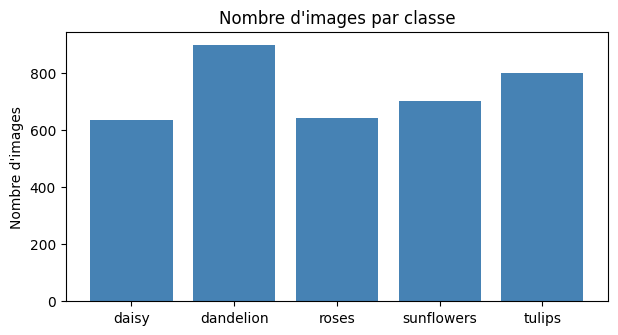

In [29]:
import collections
import matplotlib.pyplot as plt

# Correction du chemin : le dossier extrait contient un sous-dossier 'flower_photos'
if DATA_DIR.name == "flower_photos" and (DATA_DIR / "flower_photos").exists():
    DATA_DIR = DATA_DIR / "flower_photos"

# Recalcul des classes réelles
CLASS_NAMES = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())

records = []  # couples (chemin, classe) pour chaque fichier image
others = []   # fichiers qui ne sont pas des images
for cls in CLASS_NAMES:
    for f in sorted((DATA_DIR / cls).iterdir()):
        if f.suffix.lower() in IMAGE_EXTENSIONS:
            records.append((str(f), cls))
        else:
            others.append(f)
others += [f for f in DATA_DIR.iterdir() if f.is_file()]

counts = collections.Counter(cls for _, cls in records)
print(f"Nombre total d'images : {len(records)}")
print(f"Nombre de classes     : {len(CLASS_NAMES)}\n")
for cls in CLASS_NAMES:
    print(f"  {cls:<12} {counts[cls]:>5} images")
print(f"\nFichiers qui ne sont pas des images (ignorés) : {len(others)}")
for f in others:
    print("  -", f.name)

ratio = max(counts.values()) / min(counts.values())
print(f"\nRatio de déséquilibre (classe la plus / la moins représentée) : {ratio:.2f}")

plt.figure(figsize=(7, 3.5))
plt.bar(CLASS_NAMES, [counts[c] for c in CLASS_NAMES], color="steelblue")
plt.title("Nombre d'images par classe")
plt.ylabel("Nombre d'images")
plt.show()

### 1.3 Dimensions, formats et intégrité

Chaque fichier est ouvert avec Pillow pour relever sa taille, son mode colorimétrique et son format, et pour détecter les fichiers corrompus. Les fichiers illisibles sont écartés du reste du TP.

Images lisibles : 3670 / 3670 (corrompues : 0)
Largeur : min 143 px, max 1024 px, moyenne 365 px
Hauteur : min 159 px, max 442 px, moyenne 272 px
Modes colorimétriques : {'RGB': 3670}
Formats : {'JPEG': 3670}


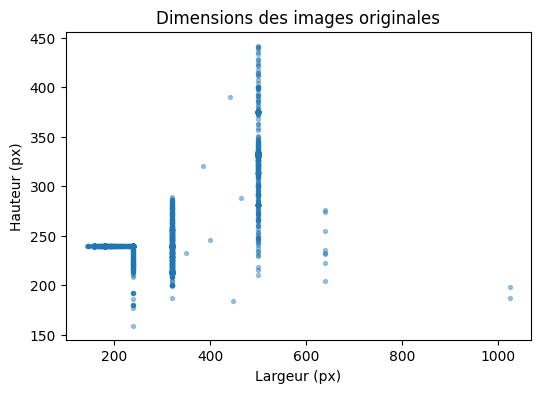

In [30]:
valid_records, corrupted, infos = [], [], []
for path, cls in records:
    try:
        with Image.open(path) as im:
            im.verify()  # contrôle d'intégrité, sans charger les pixels
        with Image.open(path) as im:  # verify() rend l'objet inutilisable : on rouvre le fichier
            infos.append({"largeur": im.width, "hauteur": im.height, "mode": im.mode, "format": im.format})
        valid_records.append((path, cls))
    except Exception as err:
        corrupted.append((path, err))

widths = np.array([i["largeur"] for i in infos])
heights = np.array([i["hauteur"] for i in infos])

print(f"Images lisibles : {len(valid_records)} / {len(records)} (corrompues : {len(corrupted)})")
for path, err in corrupted:
    print("  corrompue :", path, "->", type(err).__name__)
print(f"Largeur : min {widths.min()} px, max {widths.max()} px, moyenne {widths.mean():.0f} px")
print(f"Hauteur : min {heights.min()} px, max {heights.max()} px, moyenne {heights.mean():.0f} px")
print("Modes colorimétriques :", dict(collections.Counter(i["mode"] for i in infos)))
print("Formats :", dict(collections.Counter(i["format"] for i in infos)))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(widths, heights, s=8, alpha=0.4)
ax.set_xlabel("Largeur (px)")
ax.set_ylabel("Hauteur (px)")
ax.set_title("Dimensions des images originales")
plt.show()

### 1.4 Échantillons par classe

Quelques photos de chaque classe sont affichées pour vérifier visuellement les étiquettes et la variabilité des images.

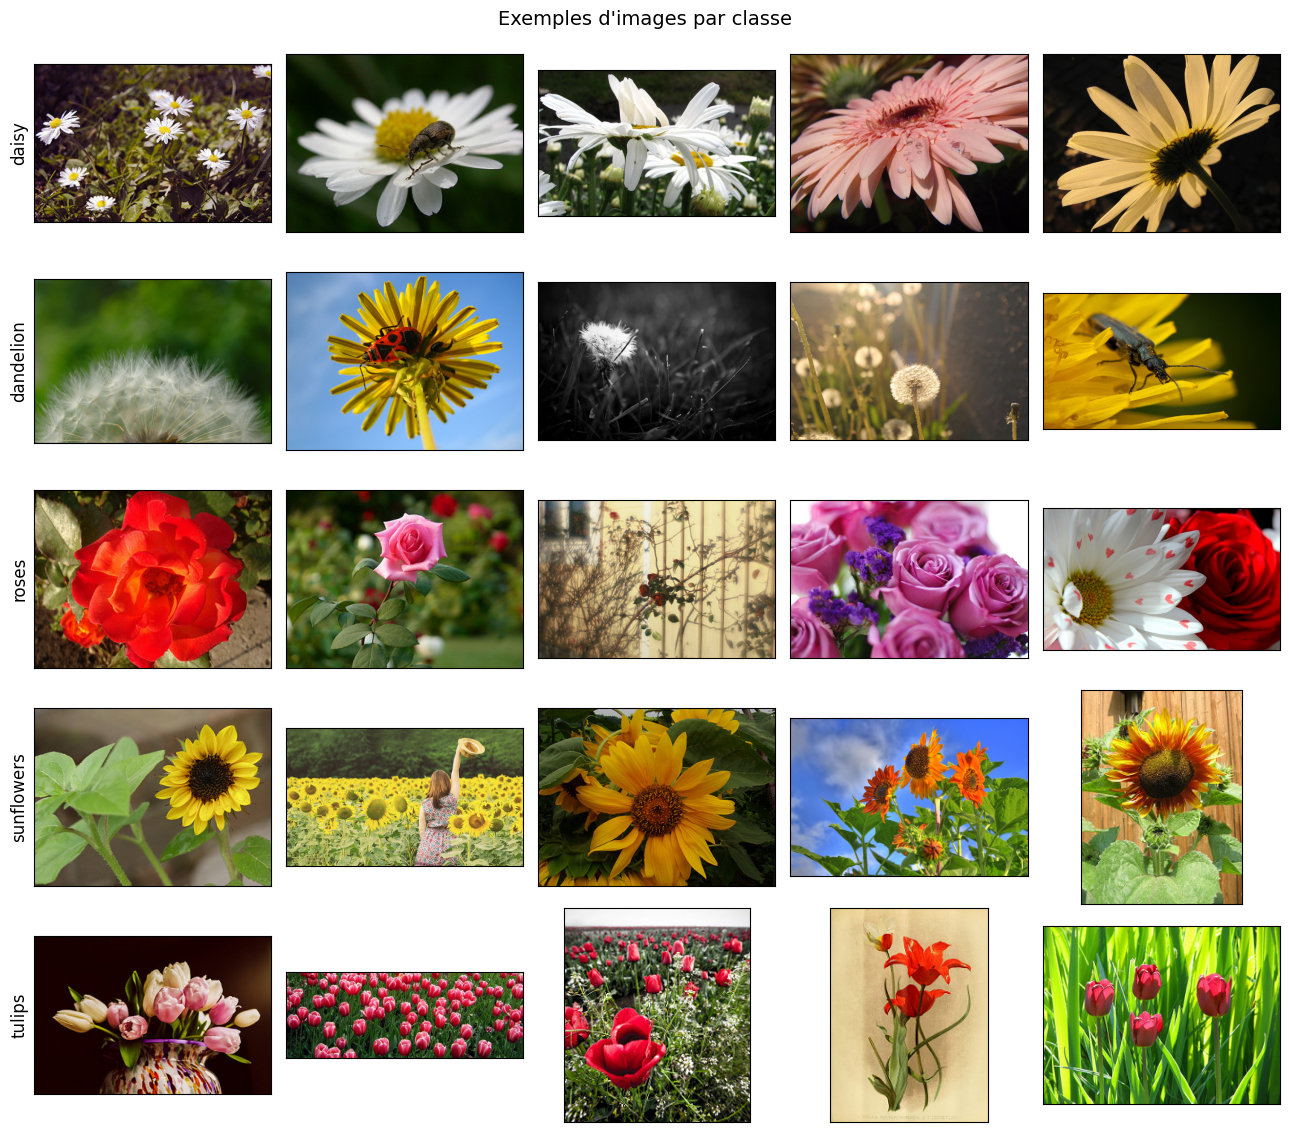

In [31]:
N_SAMPLES = 5
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASS_NAMES), N_SAMPLES, figsize=(2.6 * N_SAMPLES, 2.3 * len(CLASS_NAMES)))
for row, cls in enumerate(CLASS_NAMES):
    class_paths = [p for p, c in valid_records if c == cls]
    chosen = rng.choice(len(class_paths), size=N_SAMPLES, replace=False)
    for col, k in enumerate(chosen):
        ax = axes[row, col]
        with Image.open(class_paths[k]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(cls, fontsize=12)
plt.suptitle("Exemples d'images par classe", fontsize=14)
plt.tight_layout()
plt.show()

### 1.5 Diagnostic

**Déséquilibre des classes.** Le ratio affiché plus haut compare la classe la plus nombreuse à la moins nombreuse. Plus il est proche de 1, plus les classes sont équilibrées. Au-delà de 2 environ, un modèle risque de favoriser les classes majoritaires ; on compense alors par une pondération des classes (`class_weight`) ou par un sur-échantillonnage. Sur ce jeu de données, le déséquilibre est en principe modéré : vérifiez le ratio affiché plus haut avant de conclure.

**Variabilité des fonds et des cadrages.** Les photos ont été prises dans des conditions très différentes : fond de feuillage, d'herbe ou de ciel, éclairage naturel ou artificiel, fleur plus ou moins centrée. Le CNN doit donc apprendre des caractéristiques robustes (forme des pétales, couleurs dominantes) plutôt que des détails du fond. C'est l'une des raisons de l'augmentation de données présentée en section 4.

**Dimensions et résolution.** Les images n'ont pas toutes la même taille ni les mêmes proportions. Elles sont redimensionnées à 128 × 128 pixels : cela déforme légèrement certaines photos, mais donne des lots de taille fixe et accélère l'entraînement.

**Bruit et qualité.** Certaines photos peuvent être floues, sous-exposées ou partiellement masquées. Les fichiers illisibles, s'il y en a, sont écartés automatiquement en 1.3.

## 2. Prétraitement et construction du CNN

### 2.1 Découpage train / validation / test

Le découpage est stratifié : chaque sous-ensemble conserve les mêmes proportions de classes. Il se répartit en 70 % pour l'entraînement, 15 % pour la validation (suivi pendant l'entraînement) et 15 % pour le test, réservé à l'évaluation finale.

In [32]:
paths = [p for p, _ in valid_records]
labels = np.array([CLASS_NAMES.index(c) for _, c in valid_records])
all_idx = np.arange(len(paths))

idx_trainval, idx_test = train_test_split(all_idx, test_size=0.15, stratify=labels, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15 / 0.85,
                                      stratify=labels[idx_trainval], random_state=SEED)

for name, idx in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]:
    dist = np.bincount(labels[idx], minlength=len(CLASS_NAMES))
    detail = ", ".join(f"{c}: {n}" for c, n in zip(CLASS_NAMES, dist))
    print(f"{name:<11} {len(idx):>5} images  ->  {detail}")

train        2568 images  ->  daisy: 443, dandelion: 628, roses: 449, sunflowers: 489, tulips: 559
validation    551 images  ->  daisy: 95, dandelion: 135, roses: 96, sunflowers: 105, tulips: 120
test          551 images  ->  daisy: 95, dandelion: 135, roses: 96, sunflowers: 105, tulips: 120


### 2.2 Pipeline de données

Les images sont lues, redimensionnées et converties en tenseurs au moment de l'entraînement, grâce à `tf.data`. Les étiquettes sont encodées en *one-hot*, le format attendu par la perte *categorical cross-entropy*. Les pixels restent dans l'intervalle [0, 255] à ce stade : la normalisation est faite par une couche du modèle (`Rescaling`), ce qui permet de classer une photo brute sans prétraitement supplémentaire.

In [33]:
NUM_CLASSES = len(CLASS_NAMES)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])  # float32, valeurs entre 0 et 255
    return image, tf.one_hot(label, NUM_CLASSES)

def make_dataset(indices, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((np.array(paths)[indices], labels[indices]))
    if shuffle:
        ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    return (ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE)
              .prefetch(tf.data.AUTOTUNE))

train_ds = make_dataset(idx_train, shuffle=True)
val_ds = make_dataset(idx_val)
test_ds = make_dataset(idx_test)

images_batch, labels_batch = next(iter(train_ds))
print("Forme d'un lot d'images :", images_batch.shape, "| forme des étiquettes :", labels_batch.shape)

Forme d'un lot d'images : (32, 224, 224, 3) | forme des étiquettes : (32, 5)


### 2.3 Architecture du CNN

L'architecture suit le plan du TP : trois blocs « convolution + MaxPooling » de 32, 64 et 128 filtres, une réduction globale par moyenne (`GlobalAveragePooling2D`), une couche dense cachée de 64 neurones à activation ReLU, puis une couche de sortie à 5 neurones avec activation *softmax*. Le softmax transforme les sorties en probabilités dont la somme vaut 1.

La fonction `build_cnn` accepte aussi la liste des filtres, l'augmentation de données et le Dropout, qui serviront en section 4.

In [34]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
], name="augmentation")  # active uniquement pendant l'entraînement

def build_cnn(filters=(32, 64, 128, 256), augment=False, dropout_rate=0.0, name="cnn"):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs) if augment else inputs
    x = layers.Rescaling(1.0 / 255)(x)  # pixels ramenés dans [0, 1]
    for f in filters:
        x = layers.Conv2D(f, (3, 3), padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)  # stabilise et accélère l'apprentissage
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation="relu")(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inputs, outputs, name=name)

model = build_cnn(name="cnn_base")
model.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,397 (1.62 MB)

 Trainable params: 422,437 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 3. Compilation, entraînement et évaluation

### 3.1 Compilation

Optimiseur Adam, perte *categorical cross-entropy* (adaptée aux étiquettes *one-hot*) et métrique *accuracy*.

In [35]:
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

### 3.2 Entraînement

L'historique `history` contient, à chaque époque, la perte et la précision sur l'entraînement et sur la validation. L'arrêt anticipé (*early stopping*) interrompt l'entraînement lorsque la perte de validation ne s'améliore plus pendant 5 époques, puis restaure les meilleurs poids.

In [36]:
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-6)

history = model.fit(train_ds,
                    validation_data=val_ds,
                    epochs=EPOCHS,
                    shuffle=False,  # le jeu d'entraînement est déjà mélangé par tf.data
                    callbacks=[early_stop, reduce_lr])

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - accuracy: 0.5284 - loss: 1.1524 - val_accuracy: 0.2468 - val_loss: 1.7298 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.6125 - loss: 0.9720 - val_accuracy: 0.2613 - val_loss: 2.0798 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 89ms/step - accuracy: 0.6600 - loss: 0.8766 - val_accuracy: 0.3230 - val_loss: 1.9469 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.6690 - loss: 0.8488 - val_accuracy: 0.3702 - val_loss: 1.8494 - learning_rate: 0.0010
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.7192 - loss: 0.7429 - val_accuracy: 0.5608 - val_loss: 1.1945 - learning_rate: 3.0000e-04
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.7383 - loss: 0.6899 - val_accuracy: 0.5717 - val_loss: 1.0996 - learning_rate: 3.0000e-04
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.7399 - loss: 0.680

### 3.3 Courbes d'apprentissage

Si la précision d'entraînement continue de monter alors que celle de validation stagne ou baisse, le modèle mémorise les images d'entraînement au lieu d'apprendre des régularités : c'est le sur-apprentissage (*overfitting*). Les courbes ci-dessous permettent de le repérer.

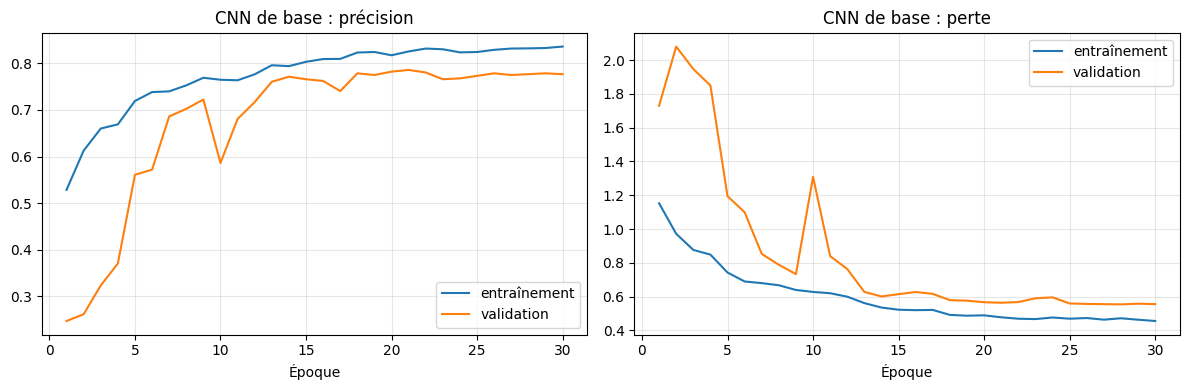

In [37]:
def plot_history(hist, title):
    h = hist.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4))
    ax_acc.plot(epochs, h["accuracy"], label="entraînement")
    ax_acc.plot(epochs, h["val_accuracy"], label="validation")
    ax_acc.set_title(f"{title} : précision")
    ax_loss.plot(epochs, h["loss"], label="entraînement")
    ax_loss.plot(epochs, h["val_loss"], label="validation")
    ax_loss.set_title(f"{title} : perte")
    for ax in (ax_acc, ax_loss):
        ax.set_xlabel("Époque")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, "CNN de base")

### 3.4 Évaluation sur le jeu de test

La précision globale (*accuracy*) donne la part de bonnes réponses. Le rapport par classe détaille trois mesures : la *precision* (parmi les images prédites dans une classe, la part correcte), le *recall* (parmi les images réelles d'une classe, la part retrouvée) et le *F1-score*, moyenne harmonique des deux. La moyenne *macro* accorde le même poids à chaque classe.

In [38]:
y_test = labels[idx_test]
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)

print(f"Perte sur le test     : {test_loss:.4f}")
print(f"Précision sur le test : {test_acc:.4f}")
print(f"F1 macro sur le test  : {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Perte sur le test     : 0.5906
Précision sur le test : 0.8058
F1 macro sur le test  : 0.8039

              precision    recall  f1-score   support

       daisy      0.794     0.811     0.802        95
   dandelion      0.780     0.867     0.821       135
       roses      0.750     0.781     0.765        96
  sunflowers      0.838     0.886     0.861       105
      tulips      0.882     0.683     0.770       120

    accuracy                          0.806       551
   macro avg      0.809     0.805     0.804       551
weighted avg      0.810     0.806     0.805       551



### 3.5 Matrice de confusion

Chaque ligne correspond à la classe réelle et chaque colonne à la classe prédite. La diagonale contient les bonnes réponses ; les cases hors diagonale indiquent quelles classes le modèle confond.

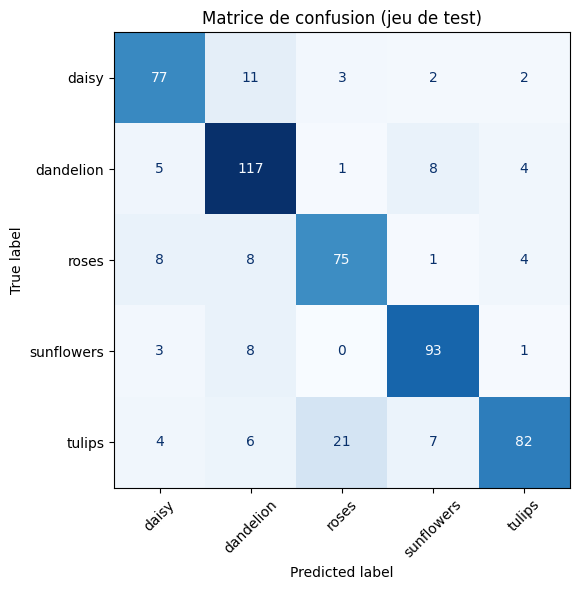

In [39]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues",
                                                             xticks_rotation=45, colorbar=False)
ax.set_title("Matrice de confusion (jeu de test)")
plt.tight_layout()
plt.show()

## 4. Pistes d'amélioration

### 4.1 Régularisation : augmentation de données et Dropout

L'augmentation de données crée, à chaque époque, des variantes aléatoires des photos (retournement horizontal, rotation, zoom), ce qui élargit artificiellement le jeu d'entraînement. Le Dropout éteint aléatoirement une partie des neurones pendant l'entraînement, pour limiter la mémorisation. Ces deux mécanismes ne sont actifs qu'à l'entraînement.

In [40]:
model_reg = build_cnn(augment=True, dropout_rate=0.3, name="cnn_regularise")
model_reg.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])

history_reg = model_reg.fit(train_ds,
                            validation_data=val_ds,
                            epochs=EPOCHS,
                            shuffle=False,  # le jeu d'entraînement est déjà mélangé par tf.data
                            callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                                               restore_best_weights=True),
                                       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                                                   patience=3, min_lr=1e-6)])
plot_history(history_reg, "CNN régularisé")

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 148ms/step - accuracy: 0.4724 - loss: 1.2961 - val_accuracy: 0.2450 - val_loss: 1.8590 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 141ms/step - accuracy: 0.5405 - loss: 1.1351 - val_accuracy: 0.2468 - val_loss: 1.9207 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.5748 - loss: 1.0597 - val_accuracy: 0.3376 - val_loss: 1.7093 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 141ms/step - accuracy: 0.5841 - loss: 1.0401 - val_accuracy: 0.4936 - val_loss: 1.2661 - learning_rate: 0.0010
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 144ms/step - accuracy: 0.6051 - loss: 0.9855 - val_accuracy: 0.5082 - val_loss: 1.2423 - learning_rate: 0.0010
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 139ms/step - accuracy: 0.6203 - loss: 0.9692 - val_accuracy: 0.5154 - val_loss: 1.3371 - learning_rate: 0.0010
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 148ms/step - accuracy: 0.6207 - loss: 0.

KeyboardInterrupt: 

### 4.2 Transfert d'apprentissage avec MobileNetV2

Le transfert d'apprentissage réutilise MobileNetV2, un réseau déjà entraîné sur ImageNet (environ 1,2 million d'images réparties en 1 000 classes). Ses couches convolutives, figées ici, savent déjà reconnaître des textures, des contours et des formes ; seule une petite tête de classification est entraînée sur nos fleurs. Les poids ImageNet sont téléchargés automatiquement au premier lancement.

In [ ]:
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                         include_top=False,
                                         weights="imagenet")
base.trainable = False  # les couches pré-entraînées sont figées

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)  # MobileNetV2 attend des pixels entre -1 et 1
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model_tl = models.Model(inputs, outputs, name="mobilenetv2_transfert")

model_tl.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="categorical_crossentropy",
                 metrics=["accuracy"])

history_tl = model_tl.fit(train_ds,
                          validation_data=val_ds,
                          epochs=EPOCHS,
                          shuffle=False,  # le jeu d'entraînement est déjà mélangé par tf.data
                          callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                             restore_best_weights=True)])
plot_history(history_tl, "MobileNetV2")

# --- Fine-tuning : on dégèle les 40 dernières couches de MobileNetV2 ---
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:  # les BatchNormalization restent figées
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_tl.compile(optimizer=tf.keras.optimizers.Adam(1e-5),  # taux très faible pour ne pas détruire les poids ImageNet
                 loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                 metrics=["accuracy"])

debut = len(history_tl.history["loss"])
history_ft = model_tl.fit(train_ds,
                          validation_data=val_ds,
                          epochs=debut + 15,
                          initial_epoch=debut,
                          shuffle=False,
                          callbacks=[callbacks.EarlyStopping(monitor="val_accuracy", patience=4,
                                                             restore_best_weights=True)])
plot_history(history_ft, "MobileNetV2 fine-tuné")


### 4.3 Comparaison des modèles

Les trois modèles sont évalués sur le même jeu de test. Une troisième piste, l'ajout de blocs convolutifs ou le changement du nombre de filtres, se teste en modifiant la liste `filters` passée à `build_cnn`, par exemple `filters=(32, 64, 128, 256)`.

Le meilleur modèle selon la précision de test est retenu pour la section 5. En toute rigueur, ce choix devrait se faire sur le jeu de validation ; ici, la comparaison sert surtout à illustrer l'effet de chaque piste.

In [ ]:
candidats = {
    "CNN de base": model,
    "CNN régularisé": model_reg,
    "MobileNetV2 (transfert)": model_tl,
}

resultats = {}
for nom, modele in candidats.items():
    _, acc = modele.evaluate(test_ds, verbose=0)
    y_p = modele.predict(test_ds, verbose=0).argmax(axis=1)
    resultats[nom] = {"accuracy": acc, "f1_macro": f1_score(y_test, y_p, average="macro")}

print(f"{'Modèle':<26}{'Accuracy':>11}{'F1 macro':>11}")
for nom, r in resultats.items():
    print(f"{nom:<26}{r['accuracy']:>11.3f}{r['f1_macro']:>11.3f}")

meilleur_nom = max(resultats, key=lambda n: resultats[n]["accuracy"])
meilleur_modele = candidats[meilleur_nom]
print(f"\nMeilleur modèle sur le jeu de test : {meilleur_nom}")

## 5. Prédiction sur une image externe

On teste le modèle sur une photo qui ne fait pas partie du jeu de données. Sur Google Colab, une fenêtre permet de téléverser votre propre photo, idéalement d'une fleur appartenant à l'une des 5 classes. Hors Colab, le notebook utilise une image du jeu de test, jamais vue pendant l'entraînement, afin que le code reste exécutable partout.

In [ ]:
try:
    from google.colab import files  # disponible uniquement dans Google Colab
    print("Téléversez une photo de fleur (idéalement de l'une des 5 classes) :")
    uploaded = files.upload()
    EXTERNAL_IMAGE = next(iter(uploaded))  # nom du fichier téléversé
    TRUE_CLASS = None                      # classe inconnue pour une image externe
except ImportError:
    EXTERNAL_IMAGE = paths[idx_test[0]]    # hors Colab : image du jeu de test (non vue en entraînement)
    TRUE_CLASS = CLASS_NAMES[labels[idx_test[0]]]

print("Image utilisée :", EXTERNAL_IMAGE)

In [ ]:
def predict_image(modele, chemin):
    image = tf.keras.utils.load_img(chemin)             # image RGB, taille d'origine
    x = tf.keras.utils.img_to_array(image)              # tableau (H, W, 3), valeurs 0-255
    x = tf.image.resize(x, [IMG_SIZE, IMG_SIZE])        # même redimensionnement qu'à l'entraînement
    lot = tf.stack([x, tf.image.flip_left_right(x)])    # test-time augmentation : image + miroir
    return modele.predict(lot, verbose=0).mean(axis=0)  # moyenne des scores softmax

probs = predict_image(meilleur_modele, EXTERNAL_IMAGE)
prediction = CLASS_NAMES[int(np.argmax(probs))]

print("Scores softmax :")
for cls, p in zip(CLASS_NAMES, probs):
    print(f"  {cls:<12} {p:7.2%}")
print(f"\nPrédiction : {prediction} (confiance {probs.max():.1%})")
if TRUE_CLASS is not None:
    print("Vraie classe :", TRUE_CLASS)

In [ ]:
fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})

ax_img.imshow(tf.keras.utils.load_img(EXTERNAL_IMAGE))
titre = f"Prédiction : {prediction}"
if TRUE_CLASS is not None:
    titre += f"\n(vraie classe : {TRUE_CLASS})"
ax_img.set_title(titre)
ax_img.axis("off")

couleurs = ["tab:green" if c == prediction else "tab:gray" for c in CLASS_NAMES]
ax_bar.barh(CLASS_NAMES, probs, color=couleurs)
ax_bar.invert_yaxis()
ax_bar.set_xlim(0, 1)
ax_bar.set_xlabel("Probabilité (softmax)")
for i, p in enumerate(probs):
    ax_bar.text(min(p + 0.01, 0.9), i, f"{p:.1%}", va="center")

plt.tight_layout()
plt.show()

## 6. Conclusion et sauvegarde

Pour rédiger la conclusion du TP, appuyez-vous sur les sorties ci-dessus. Vous pouvez examiner si le modèle de base présente du sur-apprentissage en comparant les courbes d'entraînement et de validation (section 3.3). La matrice de confusion (section 3.5) indique quelles classes sont les plus confondues, et il est utile de s'interroger sur la raison : couleurs ou formes proches, fleur partiellement masquée, fond trop chargé. Le tableau de la section 4.3 permet ensuite de mesurer le gain apporté par la régularisation puis par le transfert d'apprentissage, et d'expliquer pourquoi ce dernier est souvent très efficace avec un jeu de données de taille modeste.

Enfin, le meilleur modèle est sauvegardé ci-dessous pour être réutilisé sans ré-entraînement.

In [ ]:
meilleur_modele.save("modele_flowers.keras")
print(f"Modèle sauvegardé dans modele_flowers.keras ({meilleur_nom})")

In [41]:
import h5py
import os

h5_path = 'modele_flowers.h5'
if os.path.exists(h5_path):
    with h5py.File(h5_path, 'r') as f:
        print("Top-level keys:", list(f.keys()))
        print("Root attrs:", dict(f.attrs))
        if 'model_weights' in f:
            print("Sample weight keys:", list(f['model_weights'].keys())[:5])
        if 'model_config' in f.attrs:
            print("Has model_config ✅")
        else:
            print("No model_config ❌ (weights-only file)")
else:
    print(f"Le fichier {h5_path} n'a pas 	t	 trouv	.")

Top-level keys: []
Root attrs: {}
No model_config ❌ (weights-only file)
